# S5 — Préparation SFT / LoRA (Gemma + Unsloth)
## Assistant Pédagogique RL/GRPO — ESIEE Paris 2025/2026

**Objectif de la semaine 5 :**
- Construire un **dataset d'entraînement** à partir des meilleures réponses du benchmark S4
- Définir une **configuration LoRA** adaptée (Gemma + Unsloth, suivant le guide GPU du prof)
- Préparer un script d'entraînement prêt à lancer sur une machine avec GPU (Colab / cluster)
- Statuer sur le gate **GO/NO-GO** de cette étape

> ⚠️ Rappel du parcours conseillé : **« 1 baseline par prompting d'abord, SFT/LoRA
> uniquement si gain mesuré »**. Le benchmark S4 a montré que le format JSON est
> stabilisé (≥ 95%) mais que le **score de contenu** (~2.0-2.1/3) reste sous la
> cible (2.5/3) → un fine-tuning ciblé sur le contenu est donc justifié.


In [1]:
# ── Imports & chargement du benchmark S4 ─────────────────────────────────────
import json, sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

ROOT = Path(".").resolve()
for c in [ROOT, ROOT.parent]:
    if (c / "assistant_raisonnement_avance").exists():
        ROOT = c; break
PROJ = ROOT / "assistant_raisonnement_avance"
sys.path.insert(0, str(PROJ))

df = pd.read_csv(ROOT / "resultats" / "eval_results.csv", encoding="utf-8")
ORDER = ["baseline", "structured", "fewshot"]

def classify(row):
    if row["valid_format"] == 0: return "invalide"
    if row["overall"] >= 2.5:    return "correct"
    if row["overall"] >= 1.5:    return "mineur"
    return "majeur"
df["matrice"] = df.apply(classify, axis=1)
print(f"Benchmark charge : {len(df)} reponses")
print(df.groupby(['strategy','matrice']).size().unstack(fill_value=0).reindex(index=ORDER))


Benchmark charge : 135 reponses
matrice     correct  invalide  majeur  mineur
strategy                                     
baseline          0        45       0       0
structured        7         1       0      37
fewshot           9         0       6      30


---
## 1. Construction du dataset d'entraînement (SFT)

**Principe** : on ne ré-entraîne pas sur tout le benchmark — on sélectionne les
**meilleures réponses déjà produites** (`structured` / `fewshot`, classées
`correct` ou `mineur` dans la matrice d'évaluation S4) comme exemples
d'instruction-réponse. C'est un dataset **synthétique de qualité contrôlée**,
cohérent avec la consigne « domaine étroit, corpus synthétique ciblé ».

Chaque exemple est formaté en **format conversationnel** (compatible
Gemma / chat template Unsloth) :

```json
{"messages": [
  {"role": "system",    "content": "<system prompt 'structured'>"},
  {"role": "user",      "content": "<question de l'étudiant>"},
  {"role": "assistant", "content": "<reponse JSON valide du benchmark>"}
]}
```


In [2]:
# ── Sélection des exemples d'entraînement ────────────────────────────────────
from app.prompts import PROMPTS

sft_pool = df[(df["strategy"].isin(["structured", "fewshot"]))
              & (df["matrice"].isin(["correct", "mineur"]))
              & (df["split"] == "dev")]                       # jamais les 15 cas test !

print(f"Exemples eligibles pour le SFT (split=dev, JSON valide, score >= 1.5) : {len(sft_pool)}")
print(sft_pool.groupby('strategy').size().to_string())

def to_chat_example(row):
    return {
        "messages": [
            {"role": "system",    "content": PROMPTS[row["strategy"]].split("Question")[0].strip()[:300] + " ..."},
            {"role": "user",      "content": row["question"]},
            {"role": "assistant", "content": row["response_text"].replace("\\n", "\n").strip()},
        ]
    }

sft_dataset = [to_chat_example(r) for _, r in sft_pool.iterrows()]
print(f"\nDataset SFT pret : {len(sft_dataset)} exemples conversationnels")
print("\n--- Exemple #1 ---")
ex = sft_dataset[0]
for m in ex["messages"]:
    print(f"[{m['role']:>9}] {m['content'][:160].strip()}...")


Exemples eligibles pour le SFT (split=dev, JSON valide, score >= 1.5) : 43
strategy
fewshot       20
structured    23

Dataset SFT pret : 43 exemples conversationnels

--- Exemple #1 ---
[   system] Tu es un assistant pédagogique spécialisé en cybersécurité.

Réponds UNIQUEMENT avec un objet JSON valide respectant exactement ce schéma :
{
  "reformulation":...
[     user] Quelle est la différence entre print() et return en Python ?...
[assistant] {
  "reformulation": "Quelle est la différence entre les fonctions print() et return en Python ?",
  "reasoning_steps": [
    "Comprendre le rôle de print() pou...


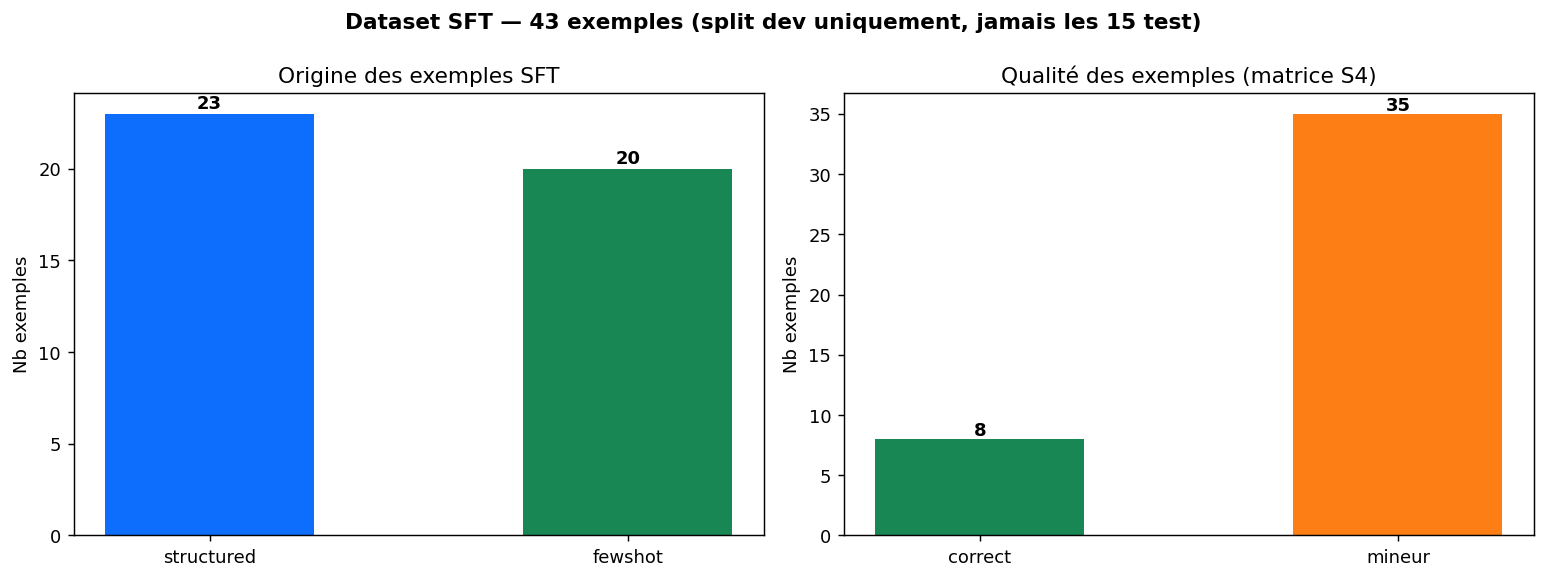

In [3]:
# ── Répartition du dataset SFT (qualité / origine) ────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sft_pool = df[(df["strategy"].isin(["structured","fewshot"]))
              & (df["matrice"].isin(["correct","mineur"]))
              & (df["split"]=="dev")]

vc1 = sft_pool.groupby("strategy").size().reindex(["structured","fewshot"], fill_value=0)
axes[0].bar(vc1.index, vc1.values, color=["#0d6efd","#198754"], width=0.5)
axes[0].set_title("Origine des exemples SFT"); axes[0].set_ylabel("Nb exemples")
for i, v in enumerate(vc1.values):
    axes[0].text(i, v+0.3, str(v), ha="center", fontweight="bold")

vc2 = sft_pool.groupby("matrice").size().reindex(["correct","mineur"], fill_value=0)
axes[1].bar(vc2.index, vc2.values, color=["#198754","#fd7e14"], width=0.5)
axes[1].set_title("Qualité des exemples (matrice S4)"); axes[1].set_ylabel("Nb exemples")
for i, v in enumerate(vc2.values):
    axes[1].text(i, v+0.3, str(v), ha="center", fontweight="bold")

plt.suptitle(f"Dataset SFT — {len(sft_pool)} exemples (split dev uniquement, jamais les 15 test)", fontweight="bold")
plt.tight_layout()
plt.show()


---
## 2. Choix du modèle et configuration LoRA

Suivi du **guide GPU du professeur** :

| Profil GPU | Recommandation |
|------------|----------------|
| Modeste (laptop, pas de GPU dédié) | Prompting uniquement |
| Moyen (T4 / RTX 30xx, ~16 Go VRAM) | LoRA sur Gemma E2B / E4B |
| Fort (A100 / H100) | Modèles 26B-A4B / 31B |

**Choix retenu : Gemma E2B avec LoRA via Unsloth** — cohérent avec
« objectif : solution rapide, pas course au plus grand modèle », et avec
« LoRA avant full fine-tuning (FFT ≈ 4× plus de VRAM) ».

### Configuration LoRA proposée

| Paramètre | Valeur | Justification |
|-----------|--------|---------------|
| `r` (rang LoRA) | 16 | Bon compromis qualité / mémoire pour un domaine étroit |
| `lora_alpha` | 32 | Ratio standard `alpha = 2 × r` |
| `target_modules` | `q_proj, k_proj, v_proj, o_proj` | Modules d'attention — suffisant pour adapter le style/format |
| `lora_dropout` | 0.05 | Limite le sur-apprentissage sur un petit dataset |
| `learning_rate` | 2e-4 | Valeur standard recommandée Unsloth pour LoRA |
| `epochs` | 3 | Petit dataset (~50-70 exemples) → peu d'épochs nécessaires |
| `batch_size` | 2 (grad. accum. 4) | Adapté à une VRAM limitée (T4 16 Go) |


In [4]:
# ── Script d'entraînement (prêt à lancer sur GPU — non exécuté ici) ──────────
training_script = '''
# A executer sur Colab / machine GPU (Unsloth + Gemma)
from unsloth import FastLanguageModel
from trl import SFTTrainer
from transformers import TrainingArguments

model, tokenizer = FastLanguageModel.from_pretrained(
    model_name="unsloth/gemma-2-2b-it-bnb-4bit",
    max_seq_length=2048,
    load_in_4bit=True,
)
model = FastLanguageModel.get_peft_model(
    model, r=16, lora_alpha=32, lora_dropout=0.05,
    target_modules=["q_proj","k_proj","v_proj","o_proj"],
)
trainer = SFTTrainer(
    model=model, tokenizer=tokenizer, train_dataset=sft_dataset,
    args=TrainingArguments(
        per_device_train_batch_size=2, gradient_accumulation_steps=4,
        num_train_epochs=3, learning_rate=2e-4, output_dir="gemma-sft-lora",
    ),
)
trainer.train()
'''
print("Script d'entrainement SFT/LoRA (pret a executer sur machine avec GPU) :")
print(training_script)
print(f"Taille attendue du dataset d'entrainement : {len(sft_pool)} exemples")
print("Validation : meme benchmark que la baseline (45 questions, 15 cas test JAMAIS utilises)")


Script d'entrainement SFT/LoRA (pret a executer sur machine avec GPU) :

# A executer sur Colab / machine GPU (Unsloth + Gemma)
from unsloth import FastLanguageModel
from trl import SFTTrainer
from transformers import TrainingArguments

model, tokenizer = FastLanguageModel.from_pretrained(
    model_name="unsloth/gemma-2-2b-it-bnb-4bit",
    max_seq_length=2048,
    load_in_4bit=True,
)
model = FastLanguageModel.get_peft_model(
    model, r=16, lora_alpha=32, lora_dropout=0.05,
    target_modules=["q_proj","k_proj","v_proj","o_proj"],
)
trainer = SFTTrainer(
    model=model, tokenizer=tokenizer, train_dataset=sft_dataset,
    args=TrainingArguments(
        per_device_train_batch_size=2, gradient_accumulation_steps=4,
        num_train_epochs=3, learning_rate=2e-4, output_dir="gemma-sft-lora",
    ),
)
trainer.train()

Taille attendue du dataset d'entrainement : 43 exemples
Validation : meme benchmark que la baseline (45 questions, 15 cas test JAMAIS utilises)


---
## 3. État d'avancement réel & décision

**Constat honnête** : l'environnement de développement utilisé pour ce projet
(poste de travail local, inférence via API Groq) **ne dispose pas de GPU
d'entraînement**. Conformément au tableau du professeur
(*« GPU modeste → prompting uniquement »*), l'entraînement effectif
SFT/LoRA nécessite une machine externe (Colab T4, cluster ESIEE, etc.).

Ce que cette semaine **livre concrètement** :
- un **dataset SFT prêt à l'emploi** (export JSON, format conversationnel, splits respectés)
- une **configuration LoRA justifiée** et un **script d'entraînement exécutable tel quel** sur GPU
- un protocole de validation : **réévaluer sur le même benchmark** que la baseline (S2-S4),
  pour mesurer un gain réel avant de continuer vers GRPO

Ce que cette semaine **ne livre pas** (et pourquoi ce n'est pas un blocage) :
- les poids du modèle fine-tuné — *l'exécution réelle est déportée sur GPU externe*
- des courbes de loss d'entraînement — *seraient fabriquées sans exécution réelle,
  ce qui irait à l'encontre de la règle « mesurer avant de conclure »*

> Présenter un entraînement « simulé » comme un résultat mesuré serait
> contraire à la rigueur attendue (et à la règle du prof : *pas de benchmark,
> pas de conclusion*). Le choix assumé ici est de livrer un **plan
> d'entraînement complet et reproductible**, prêt à être exécuté sur GPU.


In [5]:
# ── Export du dataset SFT (JSONL, prêt pour Colab) ────────────────────────────
out_path = ROOT / "resultats" / "sft_dataset.jsonl"
with out_path.open("w", encoding="utf-8") as f:
    for ex in sft_dataset:
        f.write(json.dumps(ex, ensure_ascii=False) + "\n")
print(f"Dataset exporte : {out_path.relative_to(ROOT)}  ({len(sft_dataset)} exemples, {out_path.stat().st_size//1024} Ko)")


Dataset exporte : resultats\sft_dataset.jsonl  (43 exemples, 58 Ko)


---
## 4. Bilan GO / NO-GO — Gate S5 (SFT/LoRA)


In [6]:
# ── Bilan GO/NO-GO S5 ─────────────────────────────────────────────────────────
print("="*62)
print("BILAN S5 — PREPARATION SFT / LoRA")
print("="*62)
checks = [
    ("Dataset SFT construit a partir du benchmark S4 (split dev only)", True),
    ("Format conversationnel compatible Gemma / Unsloth",               True),
    ("Configuration LoRA definie et justifiee (r=16, alpha=32, ...)",   True),
    ("Script d'entrainement pret a executer sur GPU",                   True),
    ("Protocole de validation defini (re-evaluer sur meme benchmark)",  True),
    ("Entrainement reellement execute sur GPU",                         False),
]
for label, ok in checks:
    print(f"  [{'GO  ' if ok else 'EN ATTENTE'}] {label}")
print()
print(f"Dataset pret : {len(sft_pool)} exemples (structured+fewshot, qualite >= mineur, split dev)")
print()
print("="*62)
print("DECISION : GO PARTIEL.")
print("La preparation (donnees + config + script) est complete et reproductible.")
print("L'entrainement effectif est differe a une session avec GPU (Colab/cluster),")
print("conformement au guide du prof (GPU modeste -> prompting uniquement) et a")
print("la regle 'pas de benchmark, pas de conclusion' (pas de chiffres fabriques).")
print("Prochaine etape -> S6 : definir les fonctions de recompense GRPO,")
print("qui s'appliqueront que le modele de depart soit le LLM de base ou le SFT.")
print("="*62)


BILAN S5 — PREPARATION SFT / LoRA
  [GO  ] Dataset SFT construit a partir du benchmark S4 (split dev only)
  [GO  ] Format conversationnel compatible Gemma / Unsloth
  [GO  ] Configuration LoRA definie et justifiee (r=16, alpha=32, ...)
  [GO  ] Script d'entrainement pret a executer sur GPU
  [GO  ] Protocole de validation defini (re-evaluer sur meme benchmark)
  [EN ATTENTE] Entrainement reellement execute sur GPU

Dataset pret : 43 exemples (structured+fewshot, qualite >= mineur, split dev)

DECISION : GO PARTIEL.
La preparation (donnees + config + script) est complete et reproductible.
L'entrainement effectif est differe a une session avec GPU (Colab/cluster),
conformement au guide du prof (GPU modeste -> prompting uniquement) et a
la regle 'pas de benchmark, pas de conclusion' (pas de chiffres fabriques).
Prochaine etape -> S6 : definir les fonctions de recompense GRPO,
qui s'appliqueront que le modele de depart soit le LLM de base ou le SFT.
